# 02. 정상 vs 무패턴 — 계좌쌍 과거 이력·금액 z·수신 계좌 활동량

`pair_prior_count = log1p(이전 동일 방향 계좌쌍 거래 수)`가 **0인 거래와 1건 이상인 거래**를 구분하고, 정상·무패턴 자금세탁의 네 집단을 비교합니다. 여기서 ‘1건 이상’은 로그값 1 이상이 아니라 **원래 거래 건수 1 이상**입니다.

| 비교 집단 | 정답 | 이전 동일 방향 거래 |
|---|---|---|
| normal / zero | 정상 | 0건 |
| normal / one_or_more | 정상 | 1건 이상 |
| nonpattern / zero | 무패턴 자금세탁 | 0건 |
| nonpattern / one_or_more | 무패턴 자금세탁 | 1건 이상 |

무패턴은 `Patterns.txt`에 연결된 패턴 정보가 없는 양성입니다. 이 노트북은 분포 비교이며, V10 점수 계산·모델 학습·구분 가능성의 확정은 하지 않습니다.

## 0. 실행 위치와 시간 기준

**GPU 서버 Jupyter**에서 실행합니다. 같은 폴더의 `point_in_time_analysis.py`도 함께 있어야 합니다.

입력은 기존 `code/01_prepare_parquet.ipynb`에서 같은 실행으로 만든 전체 `transactions.parquet`와 `patterns.parquet`입니다. `01_prepare_nonpattern_vs_normal.ipynb`와 같은 정의로 비교 대상을 선정하므로, 이미 만든 정상·무패턴 파일을 다시 만들 필요는 없습니다.

- **이력:** 패턴 거래를 포함한 전체 원장에서 `history.ts < target.ts`만 사용합니다. 같은 분의 거래는 전부 제외하며 `edge_id`로 선후관계를 만들지 않습니다.
- **관측 시작:** 파일의 최초 시각부터 누적합니다. 이전 거래 0건은 실제 계좌의 생애 첫 거래라는 뜻이 아닙니다.
- **기간:** 분석 시작 전 거래도 이력에 포함합니다. 모든 종료일은 미포함입니다.
- **금액 보정:** 기본값은 8월 1~7일 전체 원장으로만 계산하고 8월 8일부터 비교합니다. 분석 기간의 금액으로 보정값을 다시 맞추지 않습니다.
- **정상 보존:** 샘플링·통화·결제 방식 제한을 하지 않습니다. 기존 전처리에서 제거한 완전 중복 150행은 복원하지 않습니다.
- **활동량:** 수신자로 나타난 계좌의 과거 입금·출금을 모두 셉니다. 자기 이체는 입금 1건·출금 1건이며, 활동일과 고유 상대는 중복해서 세지 않습니다.

전체 HI-Large의 정렬·집계에는 시간이 걸립니다. 전체 거래를 pandas로 읽지 않고 파일 DuckDB와 디스크 임시 공간을 사용합니다. 피처 Parquet 외에 작업 DB·정렬용 디스크 공간도 필요합니다. 작은 분석 종료일로 먼저 실행할 수 있지만 분석 시작 전 이력은 그대로 사용합니다.

In [1]:
# 패키지가 없을 때만 현재 Jupyter 커널에 설치합니다.
# %pip install duckdb pandas numpy matplotlib

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import importlib
import sys
import json
import shutil
import duckdb
import pandas as pd
from IPython.display import display

DATASET = "HI-Large"
PROJECT_ROOT = None  # 예: Path("/workspace/money_laundry_ai_")
REFERENCE_START = "2022-08-01"
REFERENCE_END = "2022-08-08"      # 미포함: 8월 1~7일
ANALYSIS_START = "2022-08-08"
ANALYSIS_END = None              # 전체 나머지 기간. "2022-11-01"이면 10월까지
RUN_TAG = "pair_history_pit_v1"   # 재실행할 때 새 이름으로 변경
THREADS = 4
MEMORY = "6GB"
KEEP_WORK_DB = False             # 성공 후 큰 중간 DB 삭제; 실패 시 보존

if PROJECT_ROOT is None:
    here = Path.cwd().resolve()
    ROOT = next((p for p in [here, *here.parents]
                 if (p / "parquets" / DATASET / "transactions.parquet").is_file()), None)
    if ROOT is None:
        raise FileNotFoundError("GPU 서버의 저장소에서 실행하거나 PROJECT_ROOT를 지정하세요.")
else:
    ROOT = Path(PROJECT_ROOT).expanduser().resolve()
HELPER_DIR = ROOT / "code" / "nonpaten_vs_normal"
sys.path.insert(0, str(HELPER_DIR))
import point_in_time_analysis as pit
importlib.reload(pit)
BASE = ROOT / "parquets" / DATASET
TX_PATH = BASE / "transactions.parquet"
PATTERN_PATH = BASE / "patterns.parquet"
if Path(RUN_TAG).name != RUN_TAG or RUN_TAG in ("", ".", ".."):
    raise ValueError("RUN_TAG에는 폴더 이름 하나만 사용하세요.")
OUT = BASE / "nonpaten_vs_normal" / RUN_TAG
WORK = OUT / "work.duckdb"
FEATURES = OUT / "features.parquet"
print("전체 원장:", TX_PATH)
print("패턴 연결:", PATTERN_PATH)
print("결과 폴더:", OUT)
print(f"사용 가능한 디스크: {shutil.disk_usage(ROOT).free / 2**30:,.1f} GiB")

전체 원장: /workspace/money_laundry_ai_/parquets/HI-Large/transactions.parquet
패턴 연결: /workspace/money_laundry_ai_/parquets/HI-Large/patterns.parquet
결과 폴더: /workspace/money_laundry_ai_/parquets/HI-Large/nonpaten_vs_normal/pair_history_pit_v1
사용 가능한 디스크: 208.8 GiB


## 1. 계산할 피처

| 피처 | 거래 시점 이전 기준 정의 |
|---|---|
| `pair_prior_n` | 같은 방향 `(src, dst)`의 이전 거래 수 |
| `pair_prior_count` | `log1p(pair_prior_n)`; 기존 V10 피처와 같은 변환 |
| `paid_currency_z` | 기준 기간 통화별 금액 중앙값으로 `log1p(paid / scale)` 변환 후 중앙값·IQR 보정, ±8 제한 |
| `amt_z_pay_ccy` | 기준 기간 통화별 `log1p(paid)` 평균·표준편차 보정, ±10 제한 |
| `receiver_in_count` / `receiver_out_count` | 수신 계좌의 누적 입금 / 출금 거래 수 |
| `receiver_in_neighbors` / `receiver_out_neighbors` | 수신 계좌의 고유 송신 상대 / 수취 상대 수 |
| `receiver_active_days` | 입금 또는 출금이 관측된 고유 날짜 수 |
| `receiver_in_count_1h` / `receiver_out_count_1h` | `[현재 시각−60분, 현재 시각)`의 입금 / 출금 건수 |
| `receiver_in_gap_minutes` | 직전 입금부터 경과한 분. 과거 입금이 없으면 NULL |
| `receiver_in_per_active_day` | 누적 입금 건수 / 과거 활동일 수. 활동 이력이 없으면 NULL |

`paid_currency_z`의 IQR은 최소 `1e-6`, `amt_z_pay_ccy`의 분모는 표준편차 + `1e-6`입니다. 보정 기간에 없던 통화는 z를 NULL로 두고 누락 건수를 따로 셉니다. 표준편차가 0이거나 계산되지 않는 통화의 `amt_z_pay_ccy`도 NULL입니다. 원금액 `paid`는 원래 통화 단위로 보존합니다.

**기존 V10 패키지 보정표는 사용하지 않습니다.** 이 노트북의 금액 z는 분석 전 기준 기간으로 새로 계산하므로, 기존 V10의 점수·분기 임계값과 그대로 대응하지 않습니다. 기존 `features/node_features.parquet`의 구간 종료 누적값도 사용하지 않습니다.

## 2. 원장 검증 → 과거 이력 → 피처 저장 → 집계

아래 셀은 전체 처리입니다. 기존 결과 폴더가 비어 있지 않으면 중단합니다. 실패 후 재실행할 때는 `RUN_TAG`를 새 이름으로 바꿉니다.

집계의 건수는 정확 집계이고, 피처 분위수는 `approx_quantile` 근사값입니다. 보정 기간의 중앙값·IQR은 정확 분위수로 계산합니다. 라벨과 패턴 정보는 비교 대상 선정에만 사용하며 이력 집계·금액 보정에는 사용하지 않습니다.

In [3]:
if OUT.exists() and any(OUT.iterdir()):
    raise FileExistsError(f"기존 파일을 덮어쓰지 않습니다. RUN_TAG를 변경하세요: {OUT}")
OUT.mkdir(parents=True, exist_ok=True)
spill = OUT / "duckdb_tmp"
spill.mkdir(exist_ok=True)
con = duckdb.connect(str(WORK))
completed = False
try:
    con.execute(f"SET threads={int(THREADS)}")
    con.execute(f"SET memory_limit={pit.q(MEMORY)}")
    con.execute(f"SET temp_directory={pit.q(spill)}")
    con.execute("SET preserve_insertion_order=false")
    audit = pit.prepare_inputs(con, TX_PATH, PATTERN_PATH,
                               REFERENCE_START, REFERENCE_END, ANALYSIS_START, ANALYSIS_END)
    display(pd.DataFrame([audit]))
    pit.fit_amount_reference(con, REFERENCE_START, REFERENCE_END)
    amount_reference = con.execute("SELECT * FROM amount_reference ORDER BY payment_currency").df()
    display(amount_reference)
    amount_reference.to_csv(OUT / "amount_reference.csv", index=False, encoding="utf-8-sig")
    pit.build_history_states(con)
    audit.update(pit.write_features(con, FEATURES, audit["target_rows"]))
    tables = pit.summarize(con, OUT)
    audit.update({
        "dataset": DATASET, "duckdb_version": duckdb.__version__,
        "history_policy": "all observed transactions including patterns, strictly before target minute",
        "feature_scope": "cumulative since first observed transaction; 1h uses [t-60min,t)",
        "amount_reference": "fixed pre-analysis period, all labels included, not V10 package stats",
        "sampling": "none", "quantiles": "feature summaries approximate; amount reference exact",
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "inputs": {str(p): {"bytes": p.stat().st_size, "mtime_ns": p.stat().st_mtime_ns}
                   for p in (TX_PATH, PATTERN_PATH)},
        "status": "features_and_tables_complete",
    })
    (OUT / "analysis_summary.json").write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding="utf-8")
    completed = True
finally:
    con.close()
    if completed and not KEEP_WORK_DB:
        WORK.unlink(missing_ok=True)
        Path(str(WORK) + ".wal").unlink(missing_ok=True)
    if spill.exists() and not any(spill.iterdir()):
        spill.rmdir()
print("피처·집계 저장 완료:", OUT)

전체 이력 원장 준비 (패턴 거래 포함)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  완료: 22.5초


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,history_rows,history_start,history_end,all_pattern_rows,target_rows,normal_rows,nonpattern_rows,reference_start,reference_end_exclusive,analysis_start,analysis_end_exclusive
0,179702079,2022-08-01 00:00:00,2023-01-12 16:49:00,137936,164632931,164550732,82199,2022-08-01,2022-08-08,2022-08-08,None


...

집계: currency_format_counts


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

집계: z_histogram
집계: 피처별 분포 (분위수는 근사값)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

피처·집계 저장 완료: /workspace/money_laundry_ai_/parquets/HI-Large/nonpaten_vs_normal/pair_history_pit_v1


## 3. 네 집단의 규모와 월별 변화

먼저 `share_within_class`로 **정상 중 반복 거래 비중**과 **무패턴 중 반복 거래 비중**을 비교합니다. `share_within_pair_group`은 같은 이력 구간 안에서 정상·무패턴이 차지하는 비율이며 모델의 탐지율이 아닙니다.

11월 이후 거래량 급감에 따른 분포 차이를 전체 평균으로 덮지 않도록 월별 표도 함께 확인합니다. 기간을 비교할 때 금액 보정 기간은 동일하게 유지합니다.

In [4]:
# 커널을 재시작해도 저장된 집계표만 읽어 결과를 다시 볼 수 있습니다.
tables = {name: pd.read_csv(OUT / f"{name}.csv") for name in
          ["group_counts", "monthly_counts", "currency_format_counts", "z_histogram", "feature_summary"]}
display(tables["group_counts"])
display(tables["monthly_counts"])

,class_name,pair_group,n,share_within_class,share_within_pair_group
0,nonpattern,one_or_more,54992,0.669011,0.000343
1,nonpattern,zero,27207,0.330989,0.006032
2,normal,one_or_more,160067134,0.972752,0.999657
3,normal,zero,4483598,0.027248,0.993968


,month,class_name,pair_group,n,share_within_class
0,2022-08,nonpattern,one_or_more,10196,0.533515
1,2022-08,nonpattern,zero,8915,0.466485
2,2022-08,normal,one_or_more,43018504,0.966790
3,2022-08,normal,zero,1477741,0.033210
4,2022-09,nonpattern,one_or_more,17901,0.662166
5,2022-09,nonpattern,zero,9133,0.337834
6,2022-09,normal,one_or_more,54575462,0.973350
7,2022-09,normal,zero,1494232,0.026650
8,2022-10,nonpattern,one_or_more,22761,0.741304
9,2022-10,nonpattern,zero,7943,0.258696


## 4. 금액 z와 수신 계좌 활동량 비교

각 피처의 유효 건수·누락 건수·0 비율·평균·분위수를 함께 봅니다. 거래량의 긴 꼬리 때문에 평균만으로 결론 내리지 않습니다. 그림의 활동량 축은 큰 값도 보이도록 symlog를 사용하고, 금액 z 축은 선형입니다.

막대 비중은 각 정답 집단 안에서 계산합니다. 금액 z 분포는 각 네 집단의 **z가 존재하는 거래** 안에서 정규화하며, NULL은 집계표의 `missing_n`으로 확인합니다.

class_name                  nonpattern                 normal           
pair_group                 one_or_more       zero one_or_more       zero
feature                                                                 
amt_z_pay_ccy                 0.257501   0.279087   -0.106235  -0.058853
paid_currency_z               0.305666   0.327785   -0.036297   0.013834
pair_prior_n                  6.000000   0.000000   79.000000   0.000000
receiver_active_days         35.000000  10.000000   45.000000  11.000000
receiver_in_count            63.000000  13.000000  121.000000  23.000000
receiver_in_count_1h          0.000000   1.000000    0.000000   1.000000
receiver_in_gap_minutes     593.000000   7.000000   79.000000  12.000000
receiver_in_neighbors         4.000000   4.000000    4.000000   5.000000
receiver_in_per_active_day    2.146011   1.513991    2.718238   2.129455
receiver_out_count            9.000000   6.000000   10.000000   6.000000
receiver_out_count_1h         0.000000   0.000000    0.000000   0.000000
receiver_out_neighbors        3.000000   3.000000    2.000000   3.000000

,class_name,pair_group,feature,n,valid_n,missing_n,mean,zero_rate_valid,p10,p25,p50,p75,p90,p99
0,nonpattern,one_or_more,paid_currency_z,54992,54992,0,0.416427,0.000000e+00,-0.291323,-0.090166,0.305666,0.600707,1.135640,3.893368
1,nonpattern,one_or_more,amt_z_pay_ccy,54992,54992,0,0.202453,0.000000e+00,-0.630584,-0.190036,0.257501,0.500556,0.870810,2.622496
2,nonpattern,one_or_more,pair_prior_n,54992,54992,0,41.302808,0.000000e+00,1.000000,1.000000,6.000000,66.000000,136.000000,254.000000
3,nonpattern,one_or_more,receiver_in_count,54992,54992,0,94.741035,0.000000e+00,9.000000,19.000000,63.000000,143.000000,215.000000,379.000000
4,nonpattern,one_or_more,receiver_out_count,54992,54992,0,617.950902,2.467632e-02,2.000000,4.000000,9.000000,75.000000,201.000000,601.000000
5,nonpattern,one_or_more,receiver_in_neighbors,54992,54992,0,5.686045,0.000000e+00,2.000000,3.000000,4.000000,6.000000,8.000000,23.000000
6,nonpattern,one_or_more,receiver_out_neighbors,54992,54992,0,12.810227,2.467632e-02,1.000000,2.000000,3.000000,4.000000,5.000000,8.000000
7,nonpattern,one_or_more,receiver_active_days,54992,54992,0,39.358634,0.000000e+00,8.000000,15.000000,35.000000,61.000000,79.000000,95.000000
8,nonpattern,one_or_more,receiver_in_count_1h,54992,54992,0,0.775913,6.341104e-01,0.000000,0.000000,0.000000,1.000000,2.000000,9.000000
9,nonpattern,one_or_more,receiver_out_count_1h,54992,54992,0,0.757528,9.726142e-01,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000


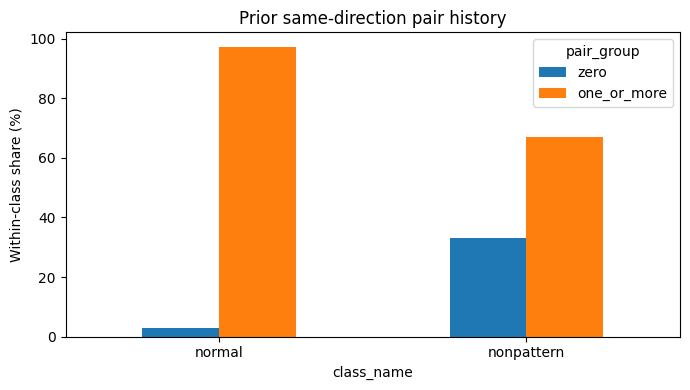

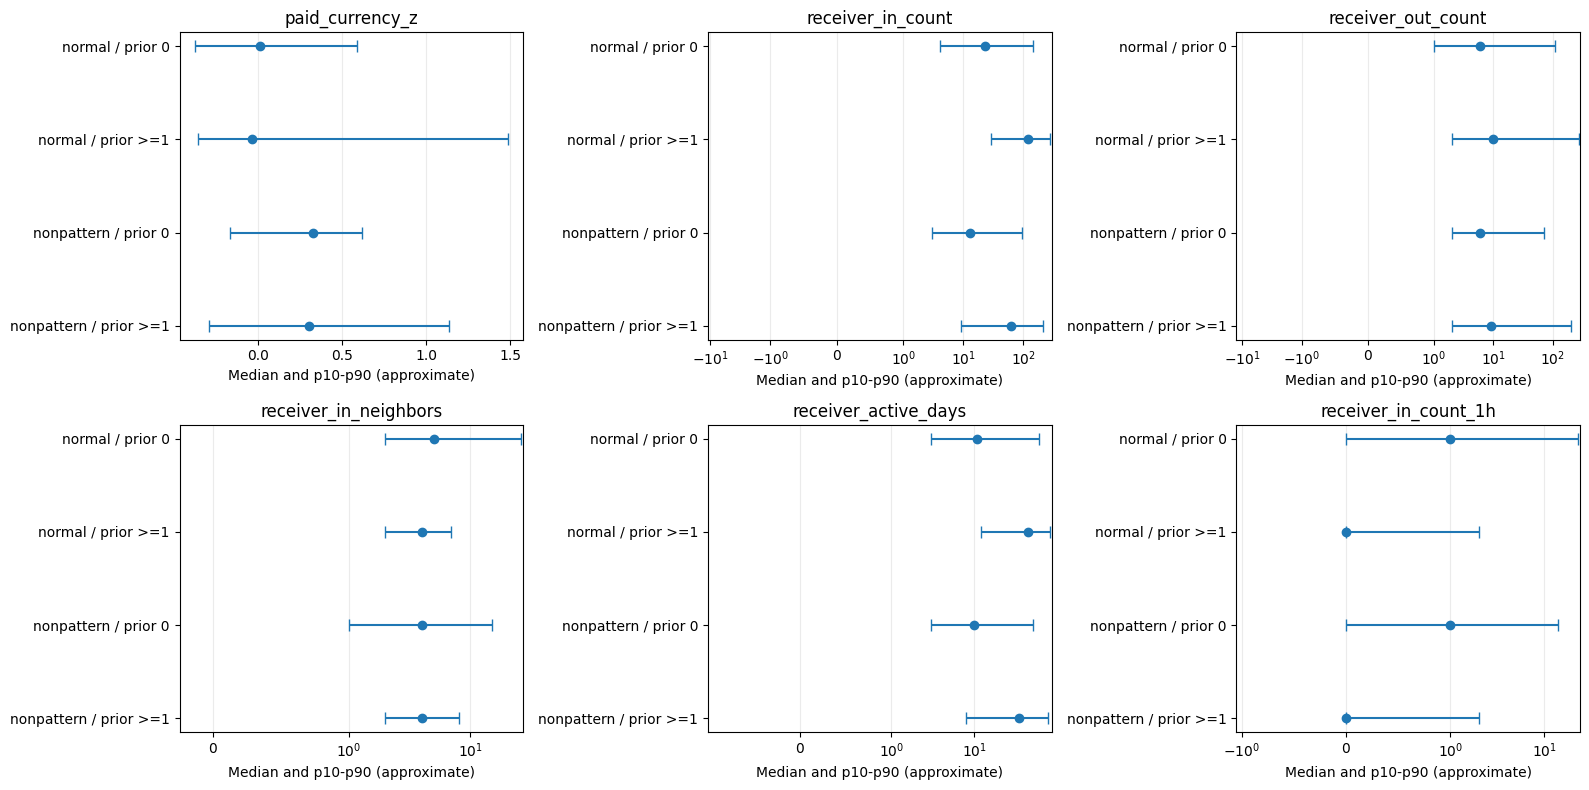

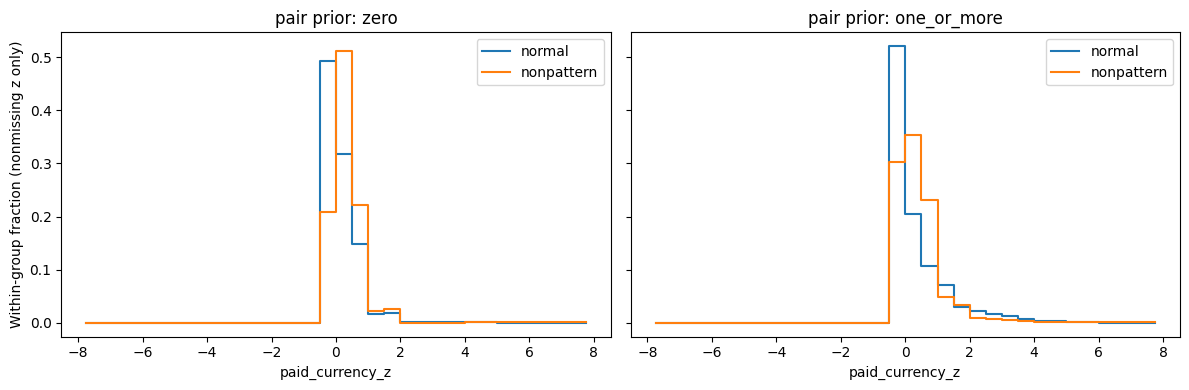

In [5]:
display(tables["feature_summary"].pivot(index="feature", columns=["class_name", "pair_group"], values="p50"))
display(tables["feature_summary"])
pit.plot_results(tables, OUT)

## 5. 통화·결제 방식 차이 확인

네 집단의 차이가 단순히 통화·결제 방식 구성 때문인지 확인하기 위한 건수표입니다. `share_within_stratum`은 같은 통화·결제 방식·과거 이력 구간에서의 집단 비율입니다. 희소한 구간의 큰 비율은 `n`과 함께 확인합니다.

분석 순서:

1. 무패턴에서 이전 동일 방향 거래가 있는 비중이 정상보다 높은지 확인합니다.
2. 같은 `pair_group` 안에서 금액 z와 수신 계좌 활동량 분포가 겹치는지 확인합니다.
3. 월별·통화·결제 방식별 구성 차이를 확인합니다.
4. 차이가 보이면 별도 시간 분리 평가에서 구분력이 유지되는지 검증합니다. 이 노트북만으로 성능 향상을 확정하지 않습니다.

In [6]:
display(tables["currency_format_counts"])
print("피처:", FEATURES)
print("집계·그림:", OUT)

,payment_currency,payment_format,pair_group,class_name,n,share_within_stratum
0,Australian Dollar,ACH,one_or_more,nonpattern,915,0.002008
1,Australian Dollar,ACH,one_or_more,normal,454716,0.997992
2,Australian Dollar,ACH,zero,nonpattern,674,0.009573
3,Australian Dollar,ACH,zero,normal,69730,0.990427
4,Australian Dollar,Bitcoin,one_or_more,normal,65,1.000000
...,...,...,...,...,...,...
233,Yuan,Credit Card,one_or_more,normal,3338498,0.999844
234,Yuan,Credit Card,zero,normal,122163,1.000000
235,Yuan,Reinvestment,one_or_more,normal,399899,1.000000
236,Yuan,Wire,one_or_more,normal,430791,1.000000


피처: /workspace/money_laundry_ai_/parquets/HI-Large/nonpaten_vs_normal/pair_history_pit_v1/features.parquet
집계·그림: /workspace/money_laundry_ai_/parquets/HI-Large/nonpaten_vs_normal/pair_history_pit_v1
